In [1]:
# Celda 1: instalación de dependencias e imports generales
# Instala/importa librerías para manejo de datos, TensorFlow/Keras,
# métricas de sklearn, split estratificado multi-label y fija seeds
# para reproducibilidad.

import os
import glob
import random
import json
from collections import Counter

os.environ["SETUPTOOLS_USE_DISTUTILS"] = "stdlib"
!pip install scikit-learn matplotlib -q

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

# no viene con sklearn, la necesitamos para el split estratificado multi-label
!pip install iterative-stratification -q
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# Celda 2: descarga del dataset desde S3
# Crea carpetas locales y sincroniza imágenes, labels, classes.txt
# y data.yaml desde el bucket de S3 hacia el entorno local.

LOCAL_DATA_DIR = "data_deteccion"
os.makedirs(f"{LOCAL_DATA_DIR}/images", exist_ok=True)
os.makedirs(f"{LOCAL_DATA_DIR}/labels", exist_ok=True)

BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_classification"

import subprocess
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/images/", f"{LOCAL_DATA_DIR}/images/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "sync", f"{BUCKET}/labels/", f"{LOCAL_DATA_DIR}/labels/", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/classes.txt", f"{LOCAL_DATA_DIR}/classes.txt", "--quiet"], check=True)
subprocess.run(["aws", "s3", "cp", f"{BUCKET}/data.yaml", f"{LOCAL_DATA_DIR}/data.yaml", "--quiet"], check=True)

n_images = len(os.listdir(f"{LOCAL_DATA_DIR}/images"))
n_labels = len(os.listdir(f"{LOCAL_DATA_DIR}/labels"))
print(f"Imagenes: {n_images} | Labels: {n_labels}")

Imagenes: 53755 | Labels: 53722


In [3]:
# Celda 3: conteo de imágenes por clase (dataset original)
# Lee classes.txt y todos los archivos de labels.

import glob
from collections import Counter

with open(f"{LOCAL_DATA_DIR}/classes.txt") as f:
    all_classes = [line.strip() for line in f if line.strip()]

orig_id_to_name = {i: name for i, name in enumerate(all_classes)}

conteo_todas = Counter()
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        clases_en_imagen = {int(l.split()[0]) for l in f if l.strip()}
    for class_id in clases_en_imagen:
        conteo_todas[orig_id_to_name[class_id]] += 1

print(f"Total de clases en el dataset original: {len(all_classes)}\n")
for name in all_classes:
    print(f"{conteo_todas.get(name, 0):>6}  {name}")


Total de clases en el dataset original: 64

  4456  Concrete spalling
  7649  Corrosion
   505  Crack
   187  Debris
   208  Detachment crack
  2499  Diagonal crack
   352  Flexural/rocking crack
    14  Large displacement
    67  Leaching
   272  Non structural damage
    25  Out-of-plane mechanism
   108  Partial/full collapse
    33  Rebar deformation/buckling
   918  Shear crack
  1261  -1-Earthquake-Induced Cracks And Collapses
   588  -2-Blistering
  2059  -3-Alveolization
   916  -4-Vegetation-Advanced Stage
   553  -5-Detachment
  1016  -6-Pitting
  2291  -7- Swelling
  1160  -8-Flaking
  2810  -9-Exfoliation
  1022  10-Vandalism
   853  11-Crumbling
  1003  12-Corrosion-Local Widespread
  2296  13-Delamination-Localized Spread
   594  14-Encrustation-Localized Spread
   611  0
  1184  1
  1667  crack
   128  damp
     4  dampness
  1003  mold
   158  peeling_paint
   111  stain
   716  stairstep_crack
   135  water_seepage
   100  Efflorescence
   214  -1.Crumbling
   461  -2.

IDs encontrados para '0' y '1': {28, 29}
Total de imágenes encontradas con clase '0' o '1': 1518


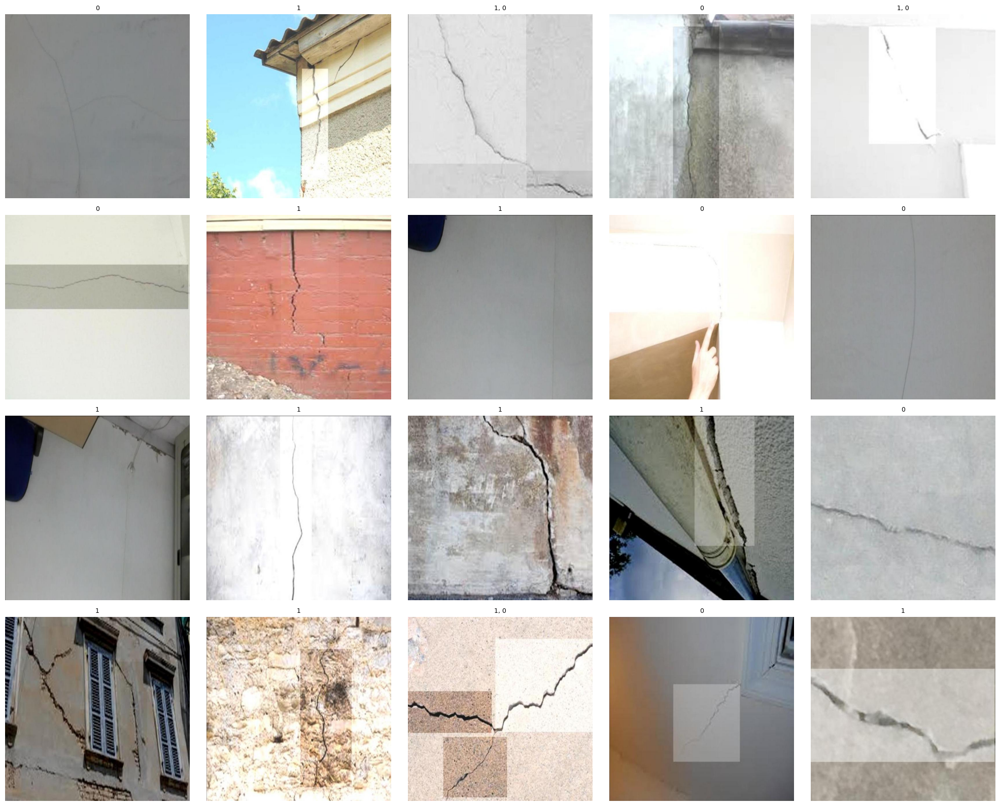

In [4]:
# Celda 4: mostrar 20 imágenes de las clases "0" y "1"
# Busca los IDs correspondientes a los nombres "0" y "1" en classes.txt,
# recorre los labels para encontrar imágenes que contengan esas clases,
# toma una muestra aleatoria de 20 y las grafica con su clase como título.
# Depende de: LOCAL_DATA_DIR, all_classes, orig_id_to_name (celdas anteriores)
import matplotlib.pyplot as plt
from PIL import Image
import random

# IDs correspondientes a los nombres "0" y "1" en classes.txt
ids_objetivo = {cid for cid, name in orig_id_to_name.items() if name in ("0", "1")}
print("IDs encontrados para '0' y '1':", ids_objetivo)

# Buscar imágenes que contengan esas clases
imagenes_encontradas = []
for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        clases_en_imagen = {int(l.split()[0]) for l in f if l.strip()}
    if clases_en_imagen & ids_objetivo:
        nombre_base = os.path.splitext(os.path.basename(label_path))[0]
        # buscar la imagen correspondiente (puede ser .jpg, .png, etc.)
        posibles = glob.glob(f"{LOCAL_DATA_DIR}/images/{nombre_base}.*")
        if posibles:
            clases_nombres = {orig_id_to_name[cid] for cid in clases_en_imagen & ids_objetivo}
            imagenes_encontradas.append((posibles[0], clases_nombres))

print(f"Total de imágenes encontradas con clase '0' o '1': {len(imagenes_encontradas)}")

# Elegir 20 al azar
random.seed(42)
muestra = random.sample(imagenes_encontradas, min(20, len(imagenes_encontradas)))

# Graficar
n = len(muestra)
cols = 5
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = axes.flatten()

for ax, (img_path, clases_nombres) in zip(axes, muestra):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(", ".join(clases_nombres), fontsize=9)
    ax.axis("off")

for ax in axes[len(muestra):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Índice armado. Clases indexadas: 64

######################################################################
GRUPO: Structural crack
######################################################################


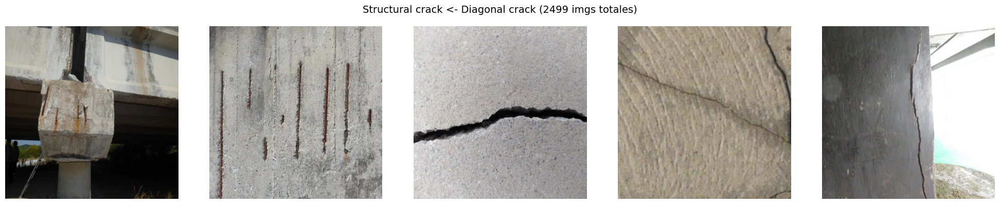

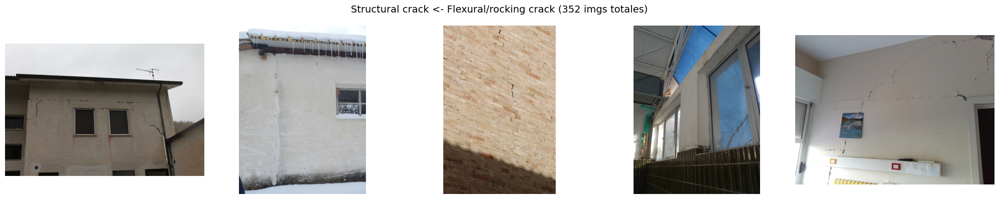

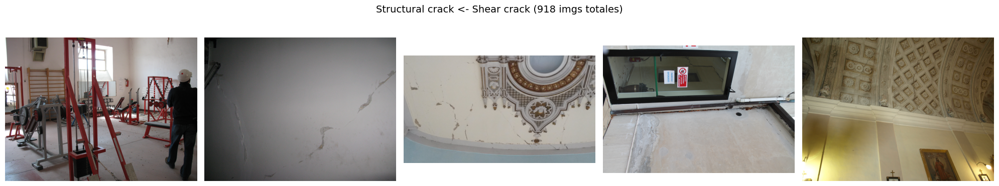

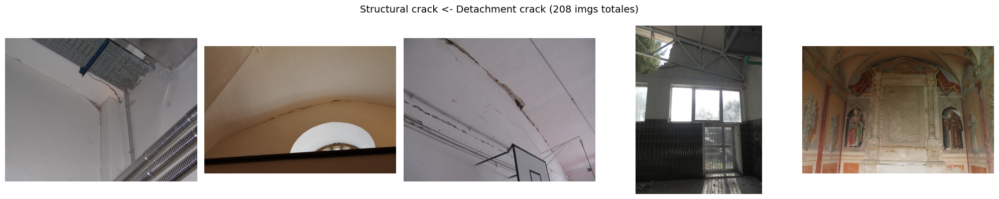

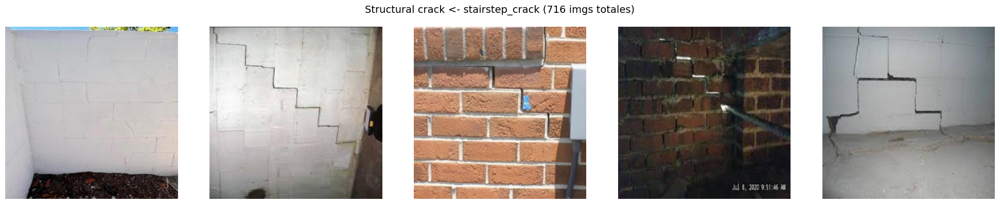

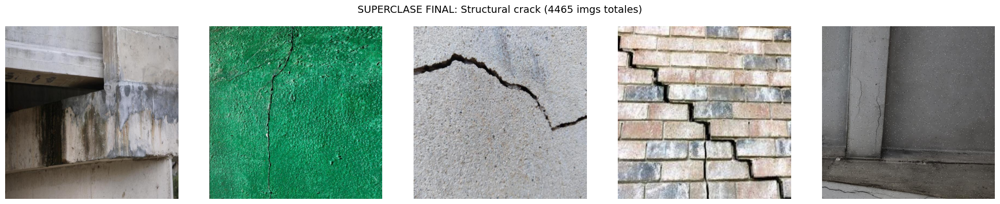


######################################################################
GRUPO: Severe structural failure
######################################################################


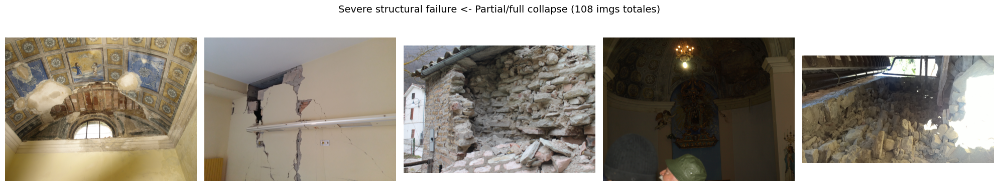

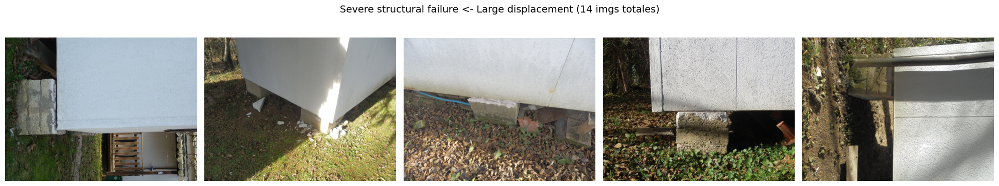

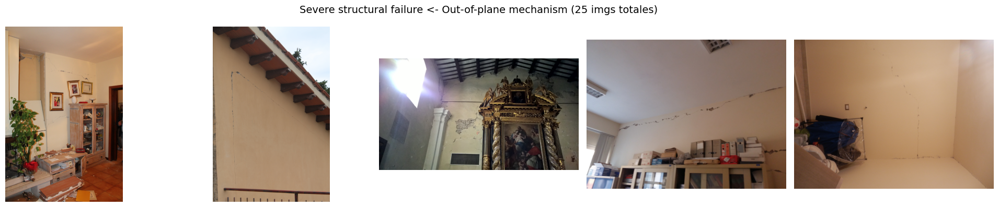

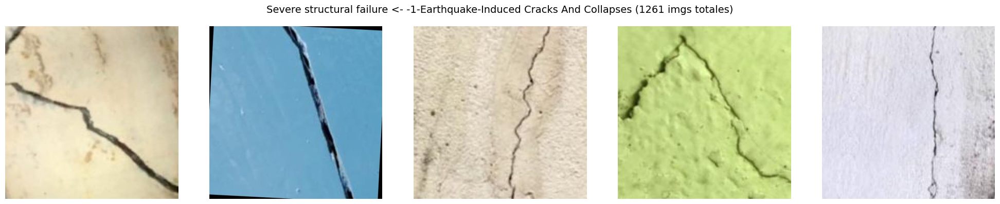

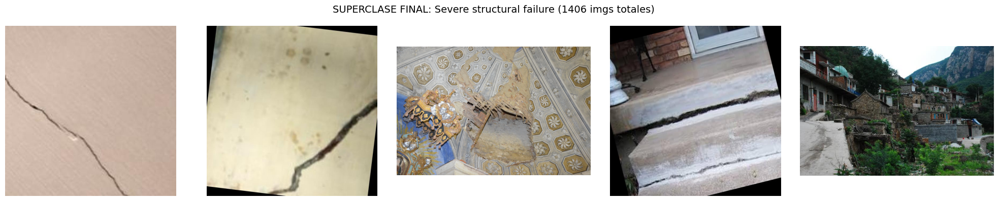


######################################################################
GRUPO: Surface flaking/exfoliation
######################################################################


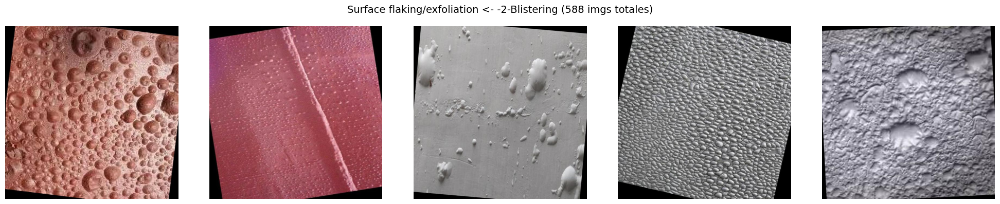

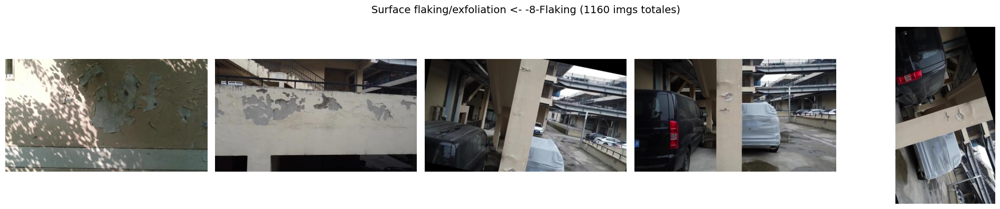

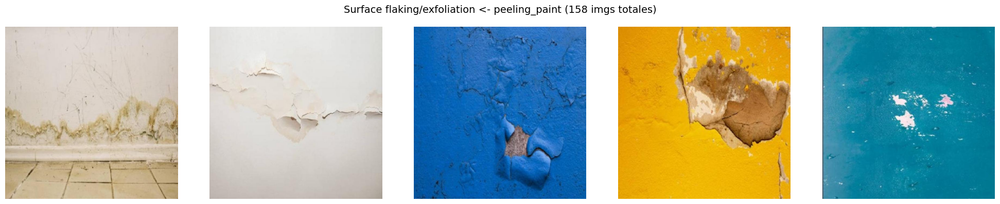

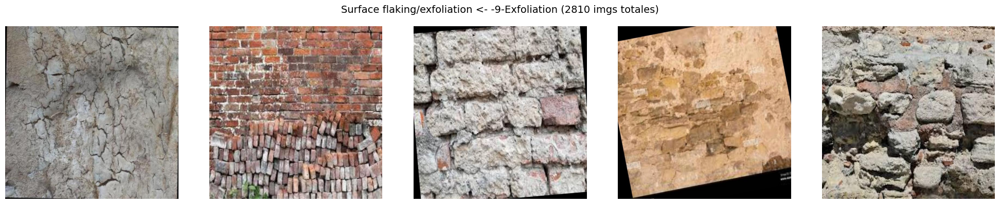

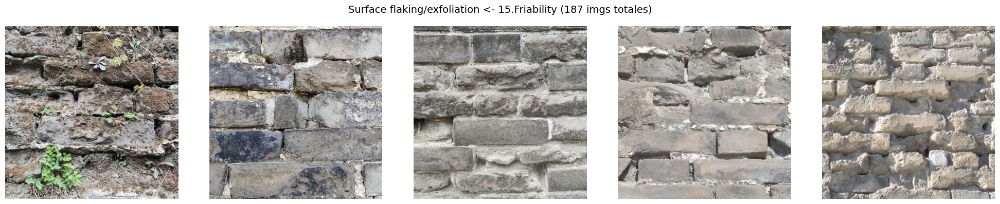

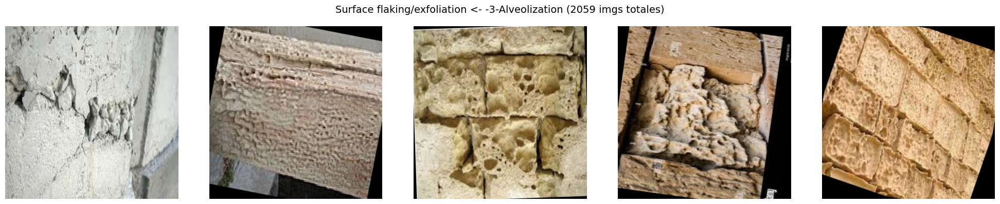

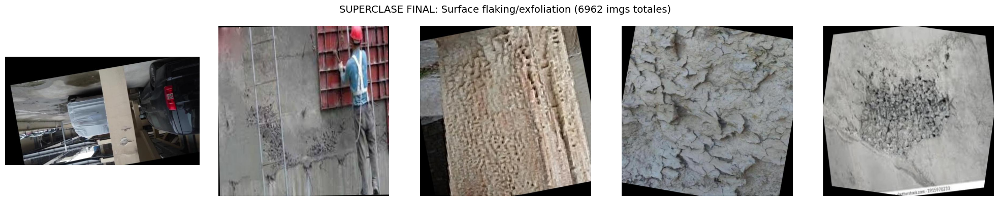


######################################################################
GRUPO: Salt weathering
######################################################################


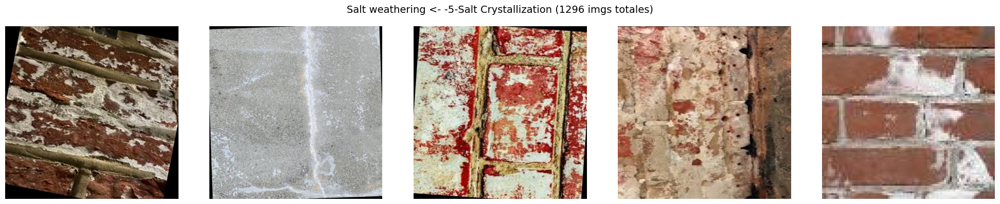

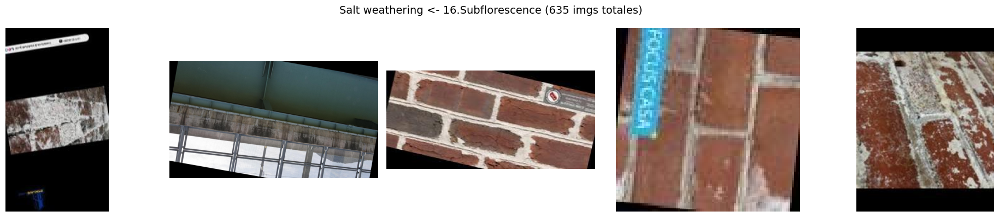

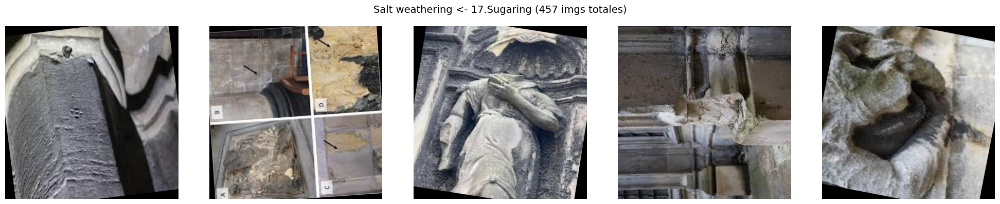

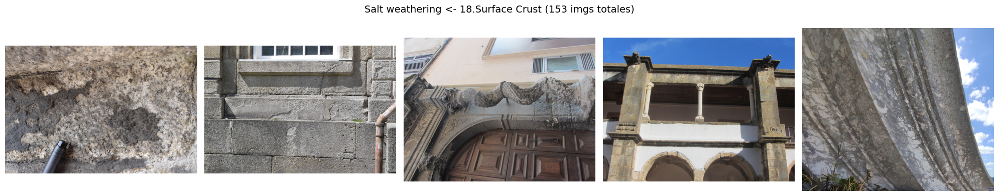

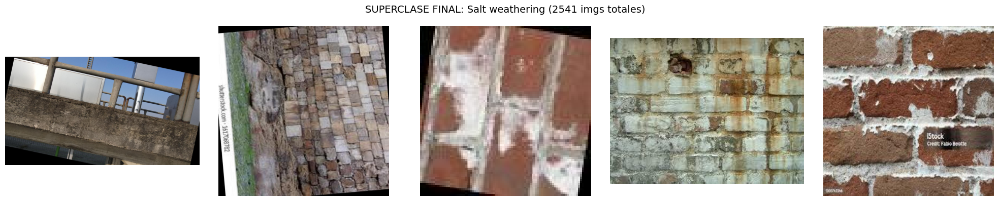


######################################################################
GRUPO: Material loss/erosion
######################################################################


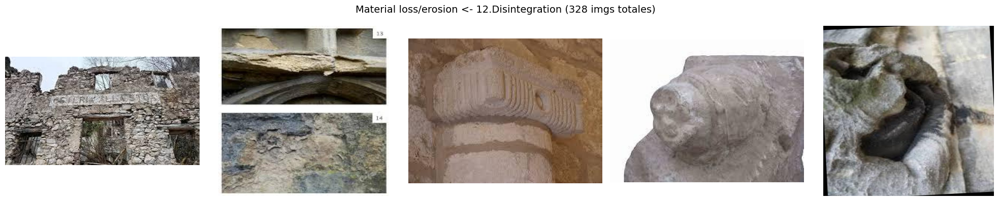

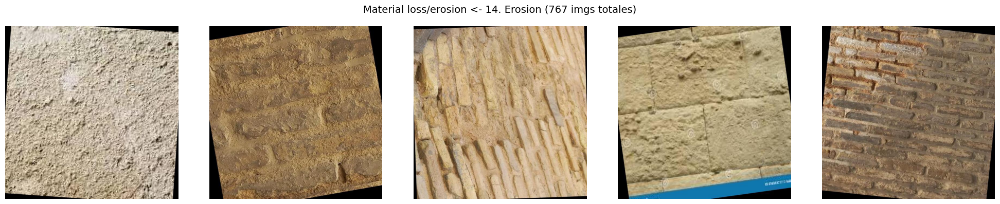

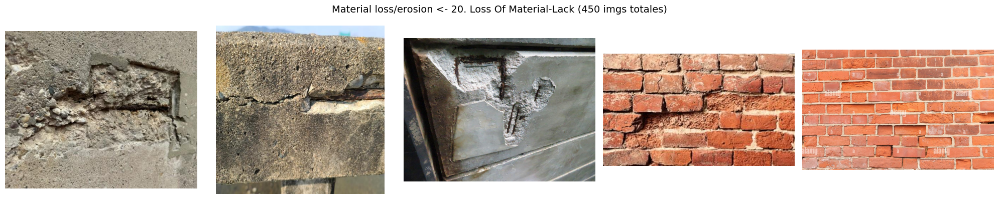

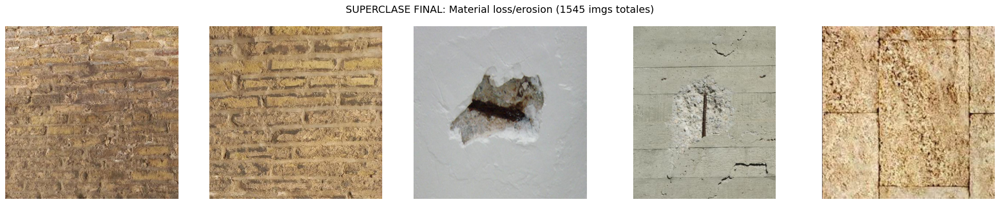


######################################################################
GRUPO: Moisture/water damage
######################################################################


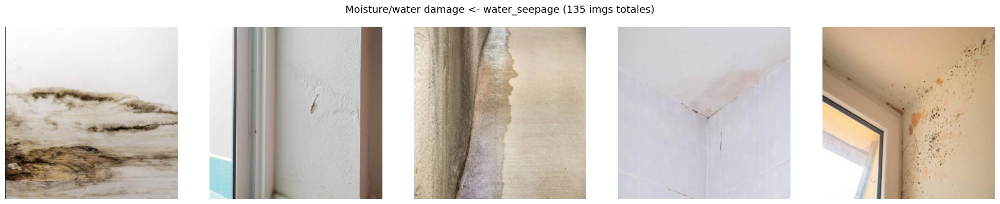

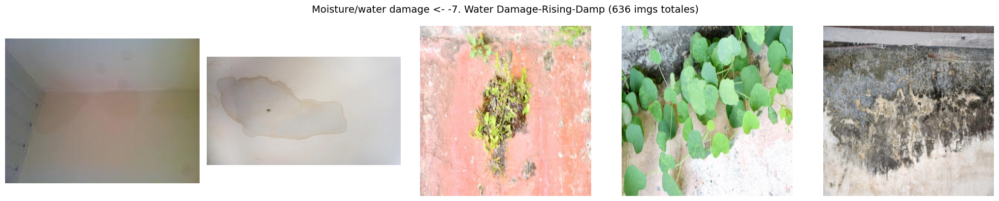

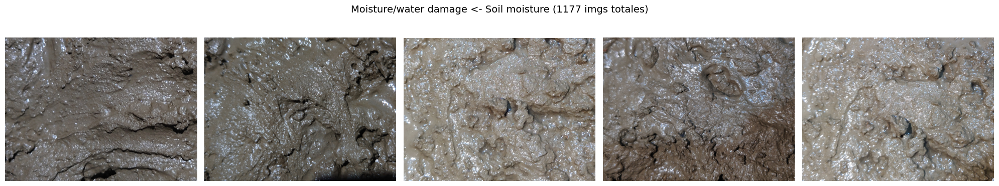

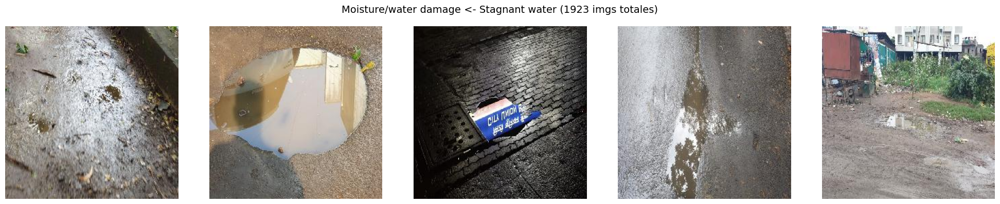

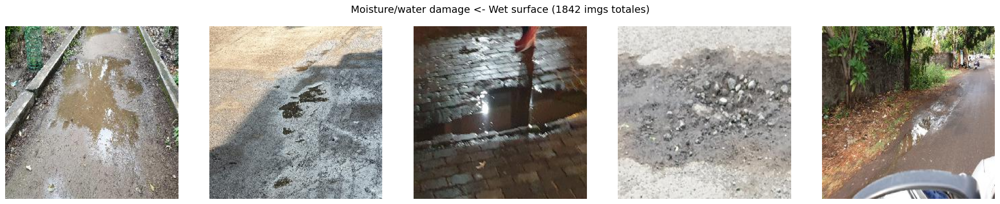

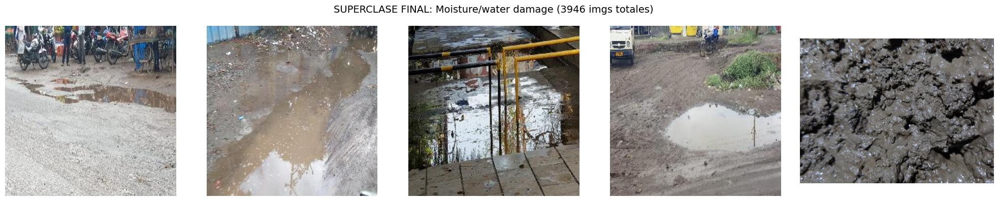


######################################################################
GRUPO: Biological growth
######################################################################


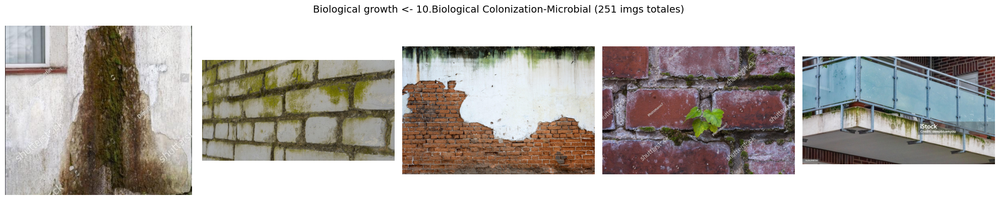

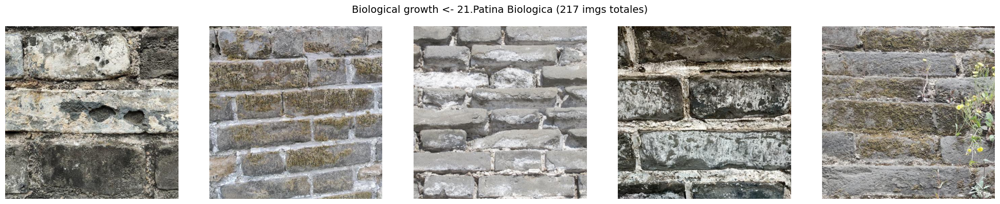

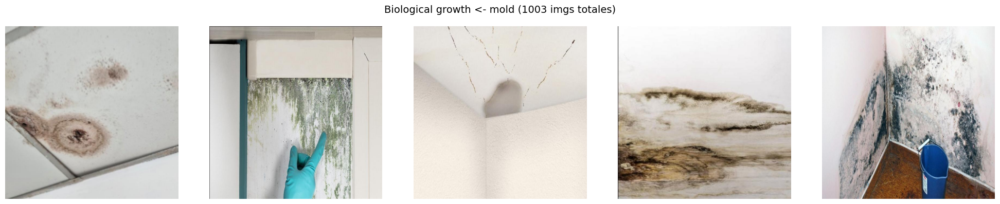

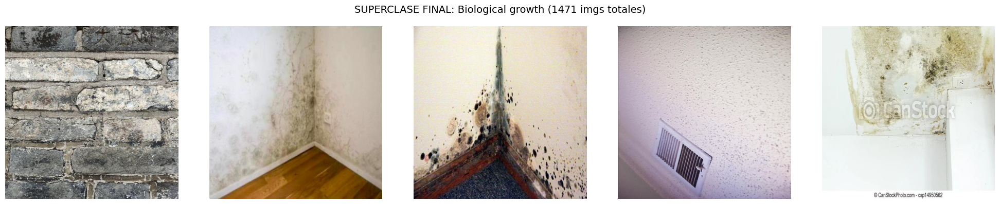


######################################################################
GRUPO: Surface deposits/incrustation
######################################################################


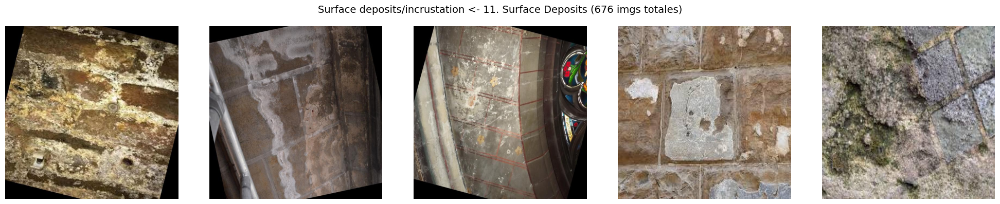

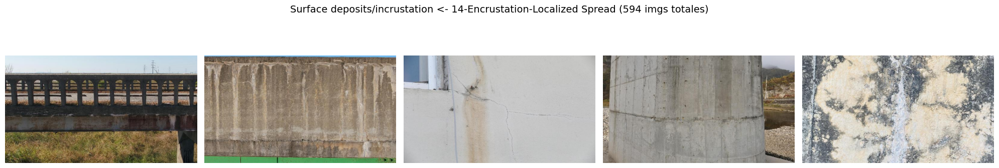

Surface deposits/incrustation <- 8-Chromatic Alteration (0 imgs totales): sin imágenes encontradas


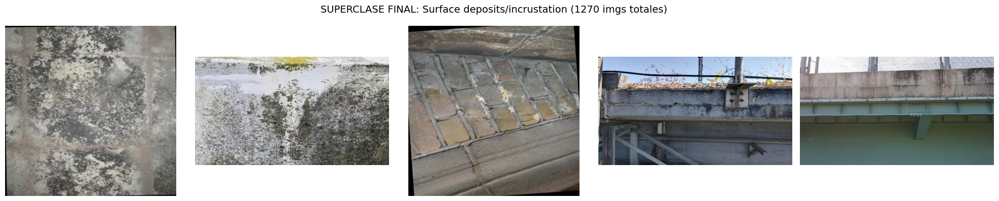

In [5]:
# Celda 5: explorar TODOS los grupos antes de fusionar (versión optimizada)
# Recorre labels/*.txt UNA sola vez y arma un índice {clase: [imagenes]}.
# Con ese índice muestra 5 imágenes de cada subclase por separado, y 5
# imágenes de la superclase resultante (unión), para cada grupo propuesto.
# Depende de: LOCAL_DATA_DIR, orig_id_to_name (celdas anteriores)
import matplotlib.pyplot as plt
from PIL import Image
import random
from collections import defaultdict

# ---- 1. Indexar UNA sola vez: nombre_clase -> lista de rutas de imagen ----
indice_clase_a_imagenes = defaultdict(list)

for label_path in glob.glob(f"{LOCAL_DATA_DIR}/labels/*.txt"):
    with open(label_path) as f:
        clases_en_imagen = {int(l.split()[0]) for l in f if l.strip()}
    if not clases_en_imagen:
        continue
    nombre_base = os.path.splitext(os.path.basename(label_path))[0]
    posibles = glob.glob(f"{LOCAL_DATA_DIR}/images/{nombre_base}.*")
    if not posibles:
        continue
    ruta_imagen = posibles[0]
    for class_id in clases_en_imagen:
        nombre_clase = orig_id_to_name[class_id]
        indice_clase_a_imagenes[nombre_clase].append(ruta_imagen)

print(f"Índice armado. Clases indexadas: {len(indice_clase_a_imagenes)}")

# ---- 2. Funciones de muestreo, usando solo el índice (sin volver a leer disco) ----
def muestra_subclase(nombre_clase, n=5, seed=42):
    rutas = indice_clase_a_imagenes.get(nombre_clase, [])
    random.seed(seed)
    return random.sample(rutas, min(n, len(rutas)))

def muestra_superclase(lista_subclases, n=5, seed=42):
    rutas = set()
    for sub in lista_subclases:
        rutas.update(indice_clase_a_imagenes.get(sub, []))
    rutas = list(rutas)
    random.seed(seed)
    return random.sample(rutas, min(n, len(rutas)))

def graficar(titulo, rutas):
    if not rutas:
        print(f"{titulo}: sin imágenes encontradas")
        return
    fig, axes = plt.subplots(1, len(rutas), figsize=(4*len(rutas), 4))
    if len(rutas) == 1:
        axes = [axes]
    for ax, ruta in zip(axes, rutas):
        img = Image.open(ruta)
        ax.imshow(img)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

def explorar_grupo(nombre_superclase, subclases, n=5):
    print(f"\n{'#'*70}\nGRUPO: {nombre_superclase}\n{'#'*70}")
    for sub in subclases:
        rutas = muestra_subclase(sub, n=n)
        graficar(f"{nombre_superclase} <- {sub} ({len(indice_clase_a_imagenes.get(sub, []))} imgs totales)", rutas)

    rutas_super = muestra_superclase(subclases, n=n)
    total_super = len(set().union(*[indice_clase_a_imagenes.get(s, []) for s in subclases]))
    graficar(f"SUPERCLASE FINAL: {nombre_superclase} ({total_super} imgs totales)", rutas_super)


# ---- Todos los grupos propuestos en la Parte 2 ----
GRUPOS = {
    "Structural crack": ["Diagonal crack", "Flexural/rocking crack", "Shear crack",
                          "Detachment crack", "stairstep_crack"],
    "Severe structural failure": ["Partial/full collapse", "Large displacement",
                                   "Out-of-plane mechanism",
                                   "-1-Earthquake-Induced Cracks And Collapses"],
    "Surface flaking/exfoliation": ["-2-Blistering", "-8-Flaking", "peeling_paint",
                                     "-9-Exfoliation", "15.Friability", "-3-Alveolization"],
    "Salt weathering": ["-5-Salt Crystallization", "16.Subflorescence",
                         "17.Sugaring", "18.Surface Crust"],
    "Material loss/erosion": ["12.Disintegration", "14. Erosion",
                               "20. Loss Of Material-Lack"],
    "Moisture/water damage": ["water_seepage", "-7. Water Damage-Rising-Damp",
                               "Soil moisture", "Stagnant water", "Wet surface"],
    "Biological growth": ["10.Biological Colonization-Microbial",
                           "21.Patina Biologica", "mold"],
    "Surface deposits/incrustation": ["11. Surface Deposits",
                                       "14-Encrustation-Localized Spread",
                                       "8-Chromatic Alteration"],
}

for nombre_superclase, subclases in GRUPOS.items():
    explorar_grupo(nombre_superclase, subclases, n=5)

Total de imagenes que caerian en al menos un grupo (si se aplica la fusion): 23315

                               imagenes  % del total cubierto  \
superclase                                                      
Surface flaking/exfoliation        6962                  29.9   
Structural crack                   4465                  19.2   
Moisture/water damage              3946                  16.9   
Salt weathering                    2541                  10.9   
Material loss/erosion              1545                   6.6   
Biological growth                  1471                   6.3   
Severe structural failure          1406                   6.0   
Surface deposits/incrustation      1270                   5.4   

                               solo esta superclase  
superclase                                           
Surface flaking/exfoliation                    6855  
Structural crack                               4402  
Moisture/water damage                          38

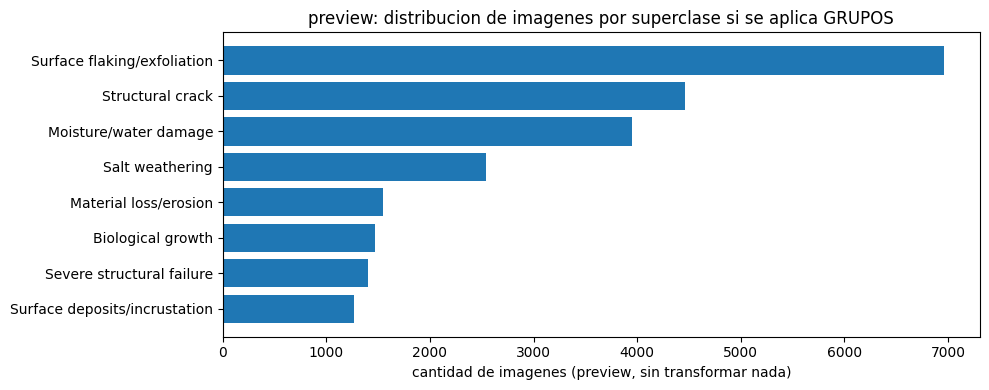

In [6]:
# Celda 5b (preview, no transforma nada): estadisticas de como quedarian
# las clases finales SI se aplica la fusion propuesta en GRUPOS.
# No crea df ni FINAL_CLASSES, todo queda en variables locales de esta
# celda (preview_df, etc.) - es solo para decidir si la fusion tiene
# sentido antes de comprometerse a construir el dataset final.
# Depende de: indice_clase_a_imagenes, GRUPOS (celda anterior)

imagenes_por_superclase_preview = {}
for superclase, subclases in GRUPOS.items():
    rutas = set()
    for sub in subclases:
        rutas.update(indice_clase_a_imagenes.get(sub, []))
    imagenes_por_superclase_preview[superclase] = rutas

total_imagenes_cubiertas = len(set().union(*imagenes_por_superclase_preview.values()))

filas_preview = []
for superclase, rutas in imagenes_por_superclase_preview.items():
    # imagenes que SOLO caen en esta superclase (no se solapan con ninguna otra superclase)
    otras_rutas = set()
    for otra_superclase, otras in imagenes_por_superclase_preview.items():
        if otra_superclase != superclase:
            otras_rutas.update(otras)
    solo_esta = rutas - otras_rutas
    filas_preview.append({
        "superclase": superclase,
        "imagenes": len(rutas),
        "% del total cubierto": round(len(rutas) / total_imagenes_cubiertas * 100, 1),
        "solo esta superclase": len(solo_esta),
    })

preview_df = pd.DataFrame(filas_preview).set_index("superclase").sort_values("imagenes", ascending=False)

print(f"Total de imagenes que caerian en al menos un grupo (si se aplica la fusion): {total_imagenes_cubiertas}\n")
print(preview_df)

plt.figure(figsize=(10, max(4, len(GRUPOS) * 0.35)))
plt.barh(preview_df.index[::-1], preview_df["imagenes"][::-1])
plt.xlabel("cantidad de imagenes (preview, sin transformar nada)")
plt.title("preview: distribucion de imagenes por superclase si se aplica GRUPOS")
plt.tight_layout()
plt.show()

Total de imagenes que caen en al menos un grupo final: 21841

                             imagenes  % del total cubierto  \
superclase                                                    
Surface flaking/exfoliation      6775                  31.0   
Structural crack                 5726                  26.2   
Moisture/water damage            3946                  18.1   
Salt weathering                  2541                  11.6   
Material loss/erosion            1545                   7.1   
Biological growth                1471                   6.7   

                             solo esta superclase  
superclase                                         
Surface flaking/exfoliation                  6733  
Structural crack                             5726  
Moisture/water damage                        3865  
Salt weathering                              2484  
Material loss/erosion                        1471  
Biological growth                            1406  

Clases excluidas

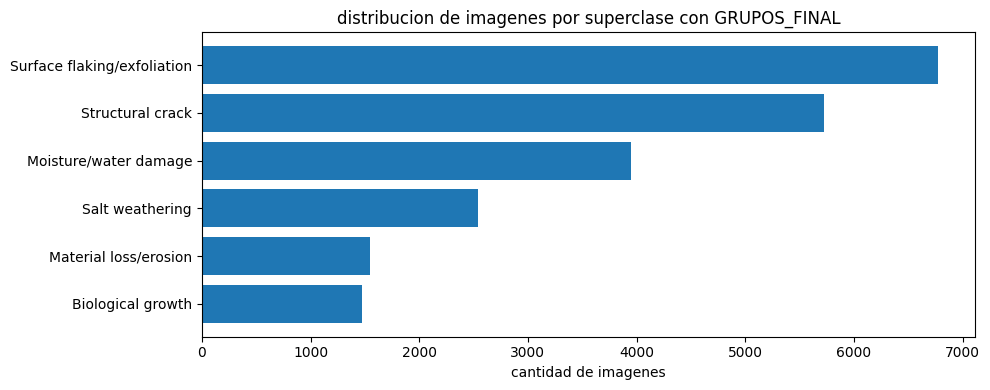

In [7]:
# Celda 5c: grupos finales (ajustados tras revisar celda 5 y 5b)
# Parte de GRUPOS (celda 5) y aplica los cambios decididos:
#   - "-1-Earthquake-Induced Cracks And Collapses" pasa a Structural crack
#   - se elimina la superclase Severe structural failure
#   - Surface flaking/exfoliation sin 15.Friability
#   - se elimina la superclase Surface deposits/incrustation
# Las clases excluidas no se asignan a ninguna superclase.
# Muestra las mismas estadisticas que la 5b pero con GRUPOS_FINAL.
# Depende de: indice_clase_a_imagenes, GRUPOS (celda 5)

GRUPOS_FINAL = {
    "Structural crack": ["Diagonal crack", "Flexural/rocking crack", "Shear crack",
                          "Detachment crack", "stairstep_crack",
                          "-1-Earthquake-Induced Cracks And Collapses"],
    "Surface flaking/exfoliation": ["-2-Blistering", "-8-Flaking", "peeling_paint",
                                     "-9-Exfoliation", "-3-Alveolization"],
    "Salt weathering": GRUPOS["Salt weathering"],
    "Material loss/erosion": GRUPOS["Material loss/erosion"],
    "Moisture/water damage": GRUPOS["Moisture/water damage"],
    "Biological growth": GRUPOS["Biological growth"],
}

CLASES_EXCLUIDAS = ["Partial/full collapse", "Large displacement",
                    "Out-of-plane mechanism", "15.Friability",
                    "11. Surface Deposits", "14-Encrustation-Localized Spread",
                    "8-Chromatic Alteration"]

imagenes_por_superclase_final = {}
for superclase, subclases in GRUPOS_FINAL.items():
    rutas = set()
    for sub in subclases:
        rutas.update(indice_clase_a_imagenes.get(sub, []))
    imagenes_por_superclase_final[superclase] = rutas

total_imagenes_final = len(set().union(*imagenes_por_superclase_final.values()))

filas_final = []
for superclase, rutas in imagenes_por_superclase_final.items():
    otras_rutas = set()
    for otra_superclase, otras in imagenes_por_superclase_final.items():
        if otra_superclase != superclase:
            otras_rutas.update(otras)
    filas_final.append({
        "superclase": superclase,
        "imagenes": len(rutas),
        "% del total cubierto": round(len(rutas) / total_imagenes_final * 100, 1),
        "solo esta superclase": len(rutas - otras_rutas),
    })

final_df_preview = pd.DataFrame(filas_final).set_index("superclase").sort_values("imagenes", ascending=False)

print(f"Total de imagenes que caen en al menos un grupo final: {total_imagenes_final}\n")
print(final_df_preview)

print("\nClases excluidas:")
for c in CLASES_EXCLUIDAS:
    print(f"  {len(indice_clase_a_imagenes.get(c, [])):>6}  {c}")

plt.figure(figsize=(10, max(4, len(GRUPOS_FINAL) * 0.35)))
plt.barh(final_df_preview.index[::-1], final_df_preview["imagenes"][::-1])
plt.xlabel("cantidad de imagenes")
plt.title("distribucion de imagenes por superclase con GRUPOS_FINAL")
plt.tight_layout()
plt.show()

In [8]:
# Celda 5d: listado de TODAS las clases originales y su destino
# Para cada una de las clases de classes.txt muestra cuantas imagenes tiene
# y a donde va: la superclase de GRUPOS_FINAL, EXCLUIDA (descartada a
# proposito en la 5c) o SIN ASIGNAR (todavia no esta en ningun grupo).
# Sirve para ver que clases grandes quedaron afuera.
# Depende de: all_classes (celda 3), indice_clase_a_imagenes (celda 5),
#             GRUPOS_FINAL, CLASES_EXCLUIDAS (celda 5c)

clase_a_superclase = {}
for superclase, subclases in GRUPOS_FINAL.items():
    for sub in subclases:
        clase_a_superclase[sub] = superclase
for c in CLASES_EXCLUIDAS:
    clase_a_superclase[c] = "EXCLUIDA"

filas_clases = []
for nombre in all_classes:
    filas_clases.append({
        "clase original": nombre,
        "imagenes": len(indice_clase_a_imagenes.get(nombre, [])),
        "destino": clase_a_superclase.get(nombre, "SIN ASIGNAR"),
    })

clases_df = pd.DataFrame(filas_clases).sort_values(["destino", "imagenes"], ascending=[True, False])

pd.set_option("display.max_rows", None)
for destino, grupo in clases_df.groupby("destino"):
    print(f"\n=== {destino} ({len(grupo)} clases, {grupo['imagenes'].sum()} imgs sumando clases) ===")
    for _, fila in grupo.iterrows():
        print(f"  {fila['imagenes']:>6}  {fila['clase original']}")

sin_asignar = clases_df[clases_df["destino"] == "SIN ASIGNAR"].sort_values("imagenes", ascending=False)
print(f"\nResumen: {len(all_classes)} clases originales | "
      f"{(clases_df['destino'].isin(GRUPOS_FINAL)).sum()} asignadas | "
      f"{(clases_df['destino'] == 'EXCLUIDA').sum()} excluidas | "
      f"{len(sin_asignar)} sin asignar")


=== Biological growth (3 clases, 1471 imgs sumando clases) ===
    1003  mold
     251  10.Biological Colonization-Microbial
     217  21.Patina Biologica

=== EXCLUIDA (6 clases, 1604 imgs sumando clases) ===
     676  11. Surface Deposits
     594  14-Encrustation-Localized Spread
     187  15.Friability
     108  Partial/full collapse
      25  Out-of-plane mechanism
      14  Large displacement

=== Material loss/erosion (3 clases, 1545 imgs sumando clases) ===
     767  14. Erosion
     450  20. Loss Of Material-Lack
     328  12.Disintegration

=== Moisture/water damage (5 clases, 5713 imgs sumando clases) ===
    1923  Stagnant water
    1842  Wet surface
    1177  Soil moisture
     636  -7. Water Damage-Rising-Damp
     135  water_seepage

=== SIN ASIGNAR (32 clases, 34752 imgs sumando clases) ===
    7649  Corrosion
    4456  Concrete spalling
    4253  Vegetation
    2296  13-Delamination-Localized Spread
    2291  -7- Swelling
    1667  crack
    1184  1
    1022  10-Vanda

In [ ]:
# Celda 5e: asignar las clases que estaban SIN ASIGNAR en la 5d
# Parte de GRUPOS_FINAL (celda 5c) y aplica las decisiones tomadas:
#   - se mantienen las 6 superclases de la 5c
#   - crack y Crack pasan a Structural crack
#   - superclases nuevas: Corrosion, Concrete spalling, Vegetation,
#     Delamination y Vandalism
#   - CLASES_EN_DUDA: no se usan para el modelo pero NO se eliminan
#     del disco, quedan pendientes para decidir mas adelante
# Al final muestra cuantas imagenes tiene cada superclase y que clases
# originales siguen sin asignar.
# Depende de: all_classes (celda 3), indice_clase_a_imagenes (celda 5),
#             GRUPOS_FINAL, CLASES_EXCLUIDAS (celda 5c)

GRUPOS_FINAL = {sup: list(subs) for sup, subs in GRUPOS_FINAL.items()}

GRUPOS_FINAL["Structural crack"] += ["crack", "Crack"]

GRUPOS_FINAL["Corrosion"] = ["Corrosion", "-2.Corrosion-Local-Widespread",
                             "12-Corrosion-Local Widespread"]
GRUPOS_FINAL["Concrete spalling"] = ["Concrete spalling"]
GRUPOS_FINAL["Vegetation"] = ["Vegetation", "-4-Vegetation-Advanced Stage"]
GRUPOS_FINAL["Delamination"] = ["13-Delamination-Localized Spread",
                                "-3.Delamination-Localized-Spread"]
GRUPOS_FINAL["Vandalism"] = ["10-Vandalism"]

# en la 5c estaba mal escrito ("8-Chromatic Alteration" sin el guion inicial)
# y ademas esa clase ahora queda en duda, asi que se saca de las excluidas
CLASES_EXCLUIDAS = [c for c in CLASES_EXCLUIDAS if c != "8-Chromatic Alteration"]

CLASES_EN_DUDA = [
    "-7- Swelling", "11-Crumbling", "23.Casting", "-5-Detachment",
    "-8-Chromatic Alteration", "Honeycomb", "-6-Pitting",
    "22.Staining", "Non structural damage", "13.Efflorescence", "-1.Crumbling",
    "Void", "Debris", "damp", "stain", "Efflorescence", "Leaching",
    "Rebar deformation/buckling", "dampness",
]

# chequeo: que todos los nombres existan en classes.txt (evita errores de tipeo)
nombres_usados = [c for subs in GRUPOS_FINAL.values() for c in subs] + CLASES_EXCLUIDAS + CLASES_EN_DUDA
mal_escritos = [c for c in nombres_usados if c not in all_classes]
repetidos = sorted({c for c in nombres_usados if nombres_usados.count(c) > 1})
print("nombres que no existen en classes.txt:", mal_escritos or "ninguno")
print("clases asignadas a mas de un lugar:", repetidos or "ninguna")

# imagenes por superclase (union de sus subclases)
imagenes_por_superclase_final = {
    sup: set().union(*[indice_clase_a_imagenes.get(s, []) for s in subs])
    for sup, subs in GRUPOS_FINAL.items()
}
total_imagenes_final = len(set().union(*imagenes_por_superclase_final.values()))

filas = []
for sup, rutas in imagenes_por_superclase_final.items():
    otras = set().union(*[r for s, r in imagenes_por_superclase_final.items() if s != sup])
    filas.append({
        "superclase": sup,
        "imagenes": len(rutas),
        "% del total": round(len(rutas) / total_imagenes_final * 100, 1),
        "solo esta superclase": len(rutas - otras),
    })
grupos_final_df = pd.DataFrame(filas).set_index("superclase").sort_values("imagenes", ascending=False)

print(f"\nSuperclases: {len(GRUPOS_FINAL)} | imagenes en al menos una: {total_imagenes_final}\n")
print(grupos_final_df)

print("\nClases EN DUDA (no se usan, no se eliminan):")
for c in CLASES_EN_DUDA:
    print(f"  {len(indice_clase_a_imagenes.get(c, [])):>6}  {c}")

asignadas = set(nombres_usados)
sin_asignar = [c for c in all_classes if c not in asignadas]
print("\nClases que siguen SIN ASIGNAR:")
for c in sin_asignar:
    print(f"  {len(indice_clase_a_imagenes.get(c, [])):>6}  {c}")

plt.figure(figsize=(10, max(4, len(GRUPOS_FINAL) * 0.4)))
plt.barh(grupos_final_df.index[::-1], grupos_final_df["imagenes"][::-1])
plt.xlabel("cantidad de imagenes")
plt.title("distribucion de imagenes por superclase (GRUPOS_FINAL despues de la 5e)")
plt.tight_layout()
plt.show()

In [ ]:
# Celda 6: construir el df final (una fila por imagen)
# Arma df con image_path, una columna 0/1 por superclase de GRUPOS_FINAL
# y la columna label (la superclase de la imagen, para multi-clase).
# Se descartan:
#   - imagenes que no caen en ninguna superclase (solo tienen clases
#     excluidas, en duda o sin asignar)
#   - imagenes que caen en mas de una superclase, porque en multi-clase
#     cada imagen tiene que tener una sola etiqueta
# Si una imagen tiene una clase en duda y otra asignada, se queda con la
# asignada (las clases en duda simplemente se ignoran).
# Depende de: indice_clase_a_imagenes (celda 5), GRUPOS_FINAL (celda 5e)

FINAL_CLASSES = list(GRUPOS_FINAL)

# imagen -> conjunto de superclases a las que pertenece
imagen_a_superclases = defaultdict(set)
for sup, subs in GRUPOS_FINAL.items():
    for sub in subs:
        for ruta in indice_clase_a_imagenes.get(sub, []):
            imagen_a_superclases[ruta].add(sup)

todas_las_imagenes = set().union(*indice_clase_a_imagenes.values())

filas = []
for ruta in sorted(todas_las_imagenes):
    sups = imagen_a_superclases.get(ruta, set())
    fila = {"image_path": ruta, "n_superclases": len(sups)}
    for cls in FINAL_CLASSES:
        fila[cls] = int(cls in sups)
    filas.append(fila)
df_todas = pd.DataFrame(filas)

sin_superclase = df_todas[df_todas["n_superclases"] == 0]
multi_superclase = df_todas[df_todas["n_superclases"] > 1]

df = df_todas[df_todas["n_superclases"] == 1].copy()
df["label"] = df[FINAL_CLASSES].idxmax(axis=1)
df = df.drop(columns="n_superclases").reset_index(drop=True)

print(f"Imagenes con al menos una etiqueta: {len(df_todas)}")
print(f"  descartadas sin superclase:         {len(sin_superclase)}")
print(f"  descartadas con mas de una:         {len(multi_superclase)}")
print(f"  quedan (una sola superclase):       {len(df)}\n")

# que combinaciones de superclases aparecen en las descartadas por tener mas de una
if len(multi_superclase):
    combos = multi_superclase[FINAL_CLASSES].apply(
        lambda f: " + ".join(c for c in FINAL_CLASSES if f[c] == 1), axis=1
    )
    print("Combinaciones mas frecuentes en las descartadas por tener mas de una:")
    print(combos.value_counts().head(10).to_string(), "\n")

print("Imagenes por clase en df:")
print(df["label"].value_counts().to_string())

In [ ]:
# Celda 6b: limpieza (corruptas, formatos no soportados y duplicados)
# Lee cada archivo UNA vez y:
#   - calcula su hash md5 (mismo hash = mismo archivo exacto)
#   - chequea que abra bien con PIL (si no, es corrupta)
#   - chequea que el formato lo pueda leer tf.io.decode_image
#     (jpeg, png, gif, bmp); otros como webp o tiff fallarian al entrenar
# Duplicados: si todas las copias tienen la misma label se deja una sola;
# si tienen labels distintas se eliminan todas (etiqueta contradictoria).
# Asi la misma foto no puede terminar en train y en test a la vez.
# Nota: solo detecta duplicados EXACTOS, no la misma foto recortada o
# redimensionada.
# Al final guarda dataset_final.csv y grupos_final.json en LOCAL_DATA_DIR
# para usarlos en cnn_damage_multiclass_training.ipynb.
# Depende de: df, FINAL_CLASSES (celda 6), GRUPOS_FINAL (celda 5e),
#             LOCAL_DATA_DIR (celda 2)
import hashlib
import io

FORMATOS_OK = {"JPEG", "PNG", "GIF", "BMP"}

hashes, estados = [], []
for i, ruta in enumerate(df["image_path"]):
    with open(ruta, "rb") as f:
        contenido = f.read()
    hashes.append(hashlib.md5(contenido).hexdigest())
    try:
        with Image.open(io.BytesIO(contenido)) as img:
            formato = img.format
            img.verify()
        estados.append("ok" if formato in FORMATOS_OK else f"formato {formato}")
    except Exception:
        estados.append("corrupta")
    if (i + 1) % 5000 == 0:
        print(f"  revisadas {i + 1}/{len(df)}")

df["hash"] = hashes
df["estado"] = estados

print("\nEstado de los archivos:")
print(df["estado"].value_counts().to_string())
df_limpio = df[df["estado"] == "ok"].copy()

# duplicados
labels_por_hash = df_limpio.groupby("hash")["label"].nunique()
hashes_conflicto = labels_por_hash[labels_por_hash > 1].index
n_copias = df_limpio["hash"].duplicated(keep=False).sum()

n_conflicto = df_limpio["hash"].isin(hashes_conflicto).sum()
df_limpio = df_limpio[~df_limpio["hash"].isin(hashes_conflicto)]
n_antes_dedup = len(df_limpio)
df_limpio = df_limpio.drop_duplicates(subset="hash", keep="first")

print(f"\nImagenes que tienen al menos una copia exacta:   {n_copias}")
print(f"  eliminadas por copias con labels distintas:    {n_conflicto}")
print(f"  eliminadas por ser copia repetida (misma label): {n_antes_dedup - len(df_limpio)}")

df = df_limpio.drop(columns=["hash", "estado"]).reset_index(drop=True)
print(f"\nDataset final: {len(df)} imagenes\n")
print(df["label"].value_counts().to_string())

# guardar para el notebook de entrenamiento multi-clase
df[["image_path", "label"]].to_csv(f"{LOCAL_DATA_DIR}/dataset_final.csv", index=False)
with open(f"{LOCAL_DATA_DIR}/grupos_final.json", "w") as f:
    json.dump(GRUPOS_FINAL, f, indent=2, ensure_ascii=False)
print(f"\nGuardado {LOCAL_DATA_DIR}/dataset_final.csv y {LOCAL_DATA_DIR}/grupos_final.json")